## Summary

We present a reusable, cloud-scalable pipeline that pairs Cellpose-SAM segmentation with on-demand GPU compute (Modal and S3) for single-cell phenotyping of high-content microscopy, demonstrated on a two-species yeast panel (*S. cerevisiae* versus *S. pombe*).

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

High-content microscopy can generate more images than a single workstation can process in a reasonable amount of time. Segmentation is the computationally intensive step, but arriving at a biological answer often also involves transferring large volumes of image data, provisioning GPUs, running sophisticated segmentation algorithms, and collecting standardized per-cell measurements. In this pub, we present a worked example that handles this entire workflow, pairing Cellpose-SAM [@pachitariu2025cellpose] with on-demand compute to scale segmentation across cloud GPUs. This shortens the path from imaging to biological interpretation and gives readers a pattern they can adapt to their own data rather than assemble from scratch. On a two-species yeast panel, we show:

1. Cellpose-SAM, combined with cloud GPU compute, can efficiently scale single-cell phenotyping across large microscopy datasets.
2. The phenotyping outputs derived from the segmentation resolve gross morphological differences between populations.

This pub is aimed at researchers developing high-throughput microscopy workflows or deciding how to scale segmentation and phenotyping. The analysis that follows runs on a dataset of two yeast species (*S. cerevisiae* and *S. pombe*), which is useful for validating the pipeline rather than a source of new biological conclusions. The workflow isn't yeast-specific — the same steps of file I/O, segmentation, parallel execution, and per-cell measurement carry over to other images, though it's best suited to imaging individual cells, such as unicellular organisms or dissociated cell populations, where cells can be segmented cleanly. For background on the tools we build on, see the Cellpose-SAM literature [@pachitariu2025cellpose] and the Modal documentation.

## How the pipeline fits together

:::{.callout-note title="Draft figure" collapse="false"}
A designed hero figure (in progress with Audrey) will replace the schematic below. The Mermaid diagram is a functional stand-in that captures the intended flow.
:::

The workflow is a straight line from raw images to per-cell measurements, with one key property: the segmentation step is identical whether it runs on one machine or hundreds of GPU containers. Scale is a deployment choice, not a code rewrite.

```{mermaid}
flowchart LR
  A["Brightfield ND2s<br/>datasets/&lt;id&gt;/raw/"] --> B["File I/O + preprocessing<br/>arcadia-microscopy-tools"]
  B --> C["Segmentation<br/>Cellpose-SAM → label masks"]
  C --> D{"Scale-out<br/>one worker per image"}
  D --> E["Derived artifacts<br/>masks · overlays · measurements"]
  E --> F["Analysis<br/>pooled per-cell morphology"]
  P["Plate map<br/>well → strain"] --> F
```

1. **Input:** brightfield ND2s in object storage, organized as `datasets/<id>/raw/`, with a plate map linking wells to strains.
2. **File I/O and preprocessing:** `arcadia-microscopy-tools` handles ND2 reading, channel and pixel-size metadata, and percentile rescaling.
3. **Segmentation:** Cellpose-SAM produces label masks; cells at the edge of the field of view are dropped.
4. **Scale-out:** one worker per image is fanned across on-demand GPU containers, each reading from and writing to shared cloud storage.
5. **Outputs (`derived/`):** label-mask TIFFs, outline-overlay JPGs for QC, and per-cell measurement CSVs (regionprops, in microns where the pixel size is known).
6. **Analysis:** pooled per-cell measurements joined to the plate map for morphology comparisons across strains.

## A two-species yeast panel

To validate the pipeline, we collected brightfield images of two diploid yeasts chosen for visually distinct morphologies — ovoid budding yeast (*S. cerevisiae* BY4743) and rod-shaped fission yeast (*S. pombe* SP286) — across 16 wells of a 96-well plate. We imaged each well at four fields in a 2×2 grid, yielding 64 ND2 files. The plate map (@tbl-plate-map) links each well to genus, species, strain, and ploidy. Culture, acquisition settings, and software versions are in @sec-methods.

At 64 images, the plate is big enough to show cloud GPU scaling in action but small enough to run and inspect end to end. And with eight replicate wells per species, we can work at the well level — comparing per-well medians across the 16 wells rather than treating every cell as an independent measurement (@tbl-features).

| Species | Strain | Wells |
| --- | --- | --- |
| *S. cerevisiae* | `BY4743` | K01–K04, L01–L04 |
| *S. pombe* | `SP286` | K05–K08, L05–L08 |

: Plate map for the two-species panel {#tbl-plate-map}

The metadata from a representative ND2 file (well K01; @tbl-nd2-meta) records the optics and pixel size used across the plate. We use that pixel size to convert the downstream morphology measurements to micrometers.

In [1]:
# | code-fold: true
# | code-summary: "Code to load the example ND2 and extract metadata"
# | label: tbl-nd2-meta
# | tbl-cap: "Acquisition metadata from a representative brightfield ND2 file."

import subprocess
from pathlib import Path

import pandas as pd
from arcadia_microscopy_tools.nikon import parse_nd2

DATASET_ID = "20260611_141152_330"
EXAMPLE_ND2 = "WellK01_PointK01_0000_Channelbrightfield_Seq0000.nd2"
RAW_DIR = Path("scratch/sample_data") / DATASET_ID / "raw"
nd2_path = RAW_DIR / EXAMPLE_ND2

if not nd2_path.exists():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    src = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/raw/{EXAMPLE_ND2}"
    try:
        subprocess.run(["aws", "s3", "cp", src, str(nd2_path)], check=True, capture_output=True)
    except (FileNotFoundError, subprocess.CalledProcessError):
        from analysis.sample_data import fetch_sample_nd2s

        nd2_path = fetch_sample_nd2s(DATASET_ID, RAW_DIR, limit=1)[0]

meta = parse_nd2(nd2_path)
cm = meta.channel_metadata_list[0]

pd.DataFrame.from_dict(
    {
        "file": nd2_path.name,
        "channel": cm.channel.name,
        "objective": cm.optics.objective,
        "magnification": cm.optics.magnification,
        "NA": cm.optics.numerical_aperture,
        "pixel_size_um": cm.resolution.xy_step_um,
        "exposure_s": cm.acquisition.exposure_time_s,
    },
    orient="index",
    columns=["value"],
)

,value
file,WellK01_PointK01_0000_Channelbrightfield_Seq00...
channel,BRIGHTFIELD
objective,PLAN APO λD 40x OFN25 DIC N2
magnification,40
NA,0.95
pixel_size_um,0.1625
exposure_s,0.01


## Demo: single-cell segmentation at scale

::: {.callout-note title="What the demo runs, and what the analysis uses"}
The demo runs a few images end to end so we can watch the pipeline work. The analysis below uses the precomputed full-plate measurements, so both species are present.
:::

The cells that follow run Cellpose-SAM [@pachitariu2025cellpose] through `arcadia-microscopy-tools`: they segment cells in the brightfield images and write label masks, quality-control overlays, and per-cell measurement tables. The same segmentation code runs in one of two interchangeable modes, chosen automatically so the notebook works with or without our cloud infrastructure. Downstream cells stay the same in either mode.

::: {.panel-tabset}

## Scaled execution (Modal + S3)

For Arcadia users with access to our cloud infrastructure, each ND2 file is processed by a separate GPU worker [@modal]. The worker reads the file from S3 and writes the artifacts back to the bucket, so a full plate can run in parallel.

## Local execution (no cloud account required)

Without a cloud account, the same Cellpose-SAM code runs locally, on CPU by default. Example ND2 files download from the public Zenodo archive once the record id is set (`CSCP_ZENODO_RECORD_ID` or `ZENODO_RECORD_ID`). Until then the local path raises an error that names those variables instead of guessing. The `limit` parameter keeps the run short. This mode can process a full plate, but sequential CPU execution is slower.

:::

The next cell calls `run_demo`, which processes `limit` images and returns the same result object in either mode. A progress bar advances as each image finishes and reports its cell count. Because the sorted file list begins with well K01, a three-image sample is *S. cerevisiae* only.

We pass `diameter=30` (pixels) and `cellprob_threshold=3.0`. Thirty pixels is Cellpose-SAM's usual default cell size; `3.0` is stricter than the library default of `0.0` and is the cutoff we used on these brightfield yeast fields to suppress debris. Library defaults and the demo values are both in @tbl-segment-config.

::: {.callout-note title="Forcing a backend" collapse="true"}
Set `CSCP_FORCE_LOCAL=1` to force the local path, or pass `backend="modal"` / `backend="local"` to `run_demo`. Details live in the [setup guide](pages/SETUP.qmd).
:::


In [2]:
# | code-fold: true
# | code-summary: "Code to trigger cell segmentation"

import time

from analysis.runner import run_demo

# Three images in both backends. Local CPU cannot do a full plate in a demo;
# files sort from well K01, so this sample is S. cerevisiae only.
# Full-plate measurements and QC overlays load separately below.
LIMIT = 3
CELL_DIAMETER = 30  # pixels
CELLPROB_THRESHOLD = 3.0

started = time.time()
run = run_demo(
    DATASET_ID,
    limit=LIMIT,
    diameter=CELL_DIAMETER,
    cellprob_threshold=CELLPROB_THRESHOLD,
)
elapsed = time.time() - started

if run.backend == "modal":
    print(f"[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/{run.output_prefix}/")
else:
    print(f"[local] Wrote artifacts to {run.output_prefix}")
print(f"Segmented {len(run.results)} image(s), {len(run.failures)} failure(s) in {elapsed:.1f}s.")


Segmenting:   0%|          | 0/3 [00:00<?, ?img/s]


Segmenting:   0%|          | 0/3 [00:36<?, ?img/s, 3512 cells · 3512 total]


Segmenting:  33%|███▎      | 1/3 [00:36<01:13, 36.52s/img, 3512 cells · 3512 total]


Segmenting:  33%|███▎      | 1/3 [00:45<01:13, 36.52s/img, 2444 cells · 5956 total]


Segmenting:  67%|██████▋   | 2/3 [00:45<00:20, 20.14s/img, 2444 cells · 5956 total]


Segmenting:  67%|██████▋   | 2/3 [00:46<00:20, 20.14s/img, 2752 cells · 8708 total]


Segmenting: 100%|██████████| 3/3 [00:46<00:00, 11.67s/img, 2752 cells · 8708 total]


Segmenting: 100%|██████████| 3/3 [00:46<00:00, 15.59s/img, 2752 cells · 8708 total]

[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/datasets/20260611_141152_330/derived/
Segmented 3 image(s), 0 failure(s) in 53.7s.


## How the full plate scales

Three images are enough to see the pipeline work. The numbers that back the scaling claim are for all 64 images (@tbl-benchmark): Modal L4 GPUs at several worker counts, plus one full-plate run on a local Apple M3 Max GPU. Throughput is images per wall-clock minute.

| Path | Images | Workers | Wall clock | Cost | Throughput |
| --- | --- | --- | --- | --- | --- |
| Modal, L4 | 64 | 1 | 1,299 s (22 min) | $0.31 | 3.0 img/min |
| Modal, L4 | 64 | 4 | 376 s (6.3 min) | $0.34 | 10 img/min |
| Modal, L4 | 64 | 16 | 119 s (2.0 min) | $0.41 | 32 img/min |
| Modal, L4 | 64 | 64 | 74 s (1.2 min) | $0.83 | 52 img/min |
| Local, Apple M3 Max GPU | 64 | 1 | 1,600 s (27 min) | — | 2.4 img/min |

: Wall clock and cost to segment the 64-image plate {#tbl-benchmark}

Wall clock falls from 22 min on one L4 to 2.0 min on 16 workers, then only to 1.2 min on 64 workers. Extra containers help until startup and GPU contention take over. At one worker, billed compute is 1,225 s against 1,299 s of wall clock, so about 70 s is startup and orchestration. At 64 workers the median image time rises from about 19 s to 34 s, and wall clock (74 s) sits at about twice that median: a cold-start floor rather than a compute floor. Cost stays near $0.30–$0.40 from 1 to 16 workers and jumps to $0.83 at 64, so the extra parallelism is mostly paying for idle GPUs waiting on the slowest image.

We default `max_containers` to 10, not because the code cannot go higher, but because our organization caps concurrent GPUs at 100 and Modal's fleet is shared. Ten workers is a courtesy ceiling. The 16-worker row is the closest measured point; it finished the plate in 2.0 min for $0.41. The local M3 Max run (1,600 s) sits in the same range as a single cloud L4.

None of these 64-image runs recorded a failure. If a worker dies, `run.failures` records the image and the error; the rest of the plate continues. The pipeline does not retry on its own. We re-run the missing files.

The scaled path is a container that reads and writes object storage. The same pattern ports to AWS Batch, Slurm, or any other queue that can run a GPU container against a bucket. A Modal account is not required to use the method, only to use this particular scheduler.


## Visual QC: segmentation overlays

The pipeline writes a segmentation overlay for each image: cell boundaries (yellow) drawn on the brightfield. @fig-overlays shows one field per species. We chose well K01 and well K05 because they are the first well of each species on the plate map (@tbl-plate-map), not because their overlays looked best. Good segmentation traces each cell tightly without merging neighbors or splitting single cells. We drop border-touching cells, because truncation would bias their measurements.


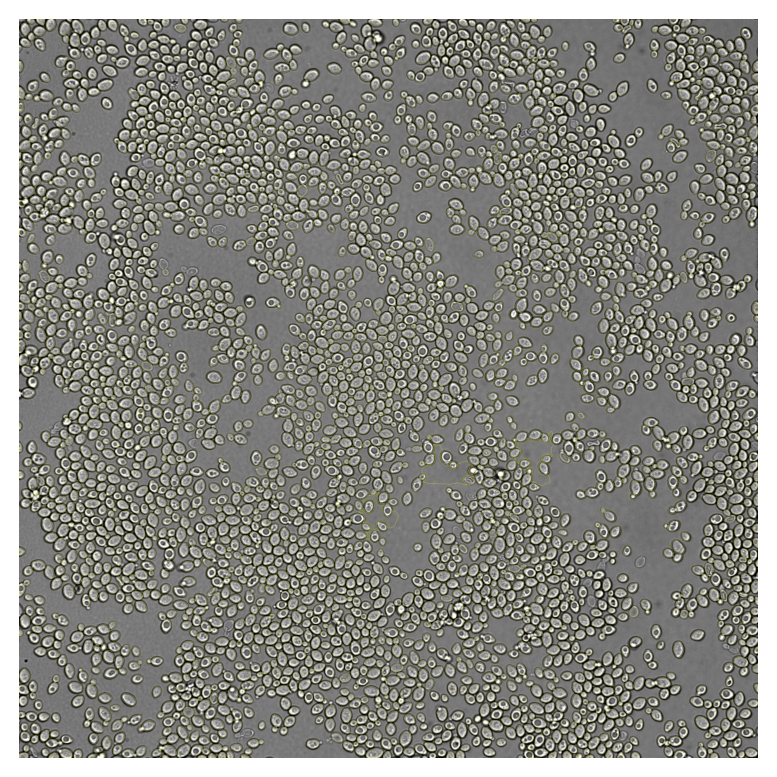

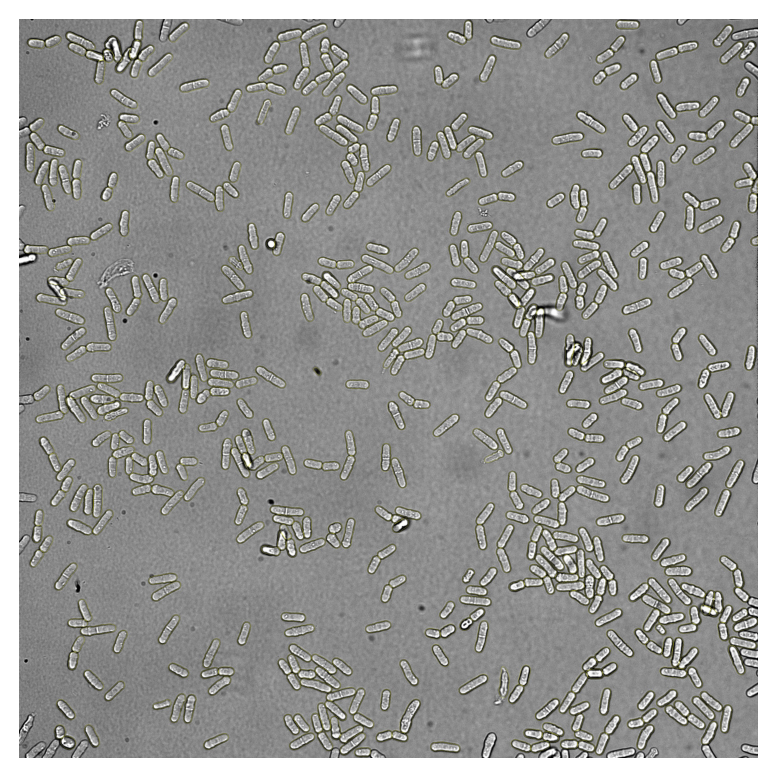

In [3]:
# | echo: false
# | label: fig-overlays
# | layout-ncol: 2
# | fig-cap: "Cellpose-SAM outlines on brightfield, one field per species."
# | fig-subcap:
# |   - "*S. cerevisiae* BY4743, well K01"
# |   - "*S. pombe* SP286, well K05"
# | fig-alt:
# |   - "Brightfield field of ovoid budding yeast with tight cell outlines."
# |   - "Brightfield field of rod-shaped fission yeast with tight cell outlines."

import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt

QC_WELLS = ("K01", "K05")


def _well(name: str) -> str | None:
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


def _from_run(well: str) -> Path | None:
    for summary in run.results:
        path = summary.get("local_overlay")
        if not path:
            continue
        path = Path(path)
        name = str(summary.get("input", ""))
        if path.exists() and _well(name) == well:
            return path
    return None


def _from_derived(well: str) -> Path | None:
    dest_dir = Path("scratch/segmentation_results")
    dest_dir.mkdir(parents=True, exist_ok=True)
    for path in sorted(dest_dir.glob("*_overlay.jpg")):
        if _well(path.name) == well:
            return path
    prefix = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/derived/overlays/"
    try:
        listed = subprocess.run(
            ["aws", "s3", "ls", prefix], check=True, capture_output=True, text=True
        )
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None
    for line in listed.stdout.splitlines():
        name = line.split()[-1] if line.split() else ""
        if not (name.endswith("_overlay.jpg") and _well(name) == well):
            continue
        dest = dest_dir / name
        try:
            subprocess.run(
                ["aws", "s3", "cp", prefix + name, str(dest)],
                check=True,
                capture_output=True,
            )
        except (FileNotFoundError, subprocess.CalledProcessError):
            return None
        return dest if dest.exists() else None
    return None


for well in QC_WELLS:
    overlay = _from_run(well) or _from_derived(well)
    if overlay is None:
        raise FileNotFoundError(
            f"No overlay for well {well}. Run the demo cell above or copy "
            f"precomputed overlays from the dataset's derived/ prefix."
        )
    fig, ax = plt.subplots()
    ax.imshow(plt.imread(overlay))
    ax.set_axis_off()
    plt.show()

## Per-cell phenotyping outputs

Each segmented object also becomes a row of shape measurements from scikit-image `regionprops` [@vanderwalt2014scikit], converted to micrometers where the pixel size is known: area, eccentricity, axis lengths, and related features (@tbl-cells). Pooling across images and joining to the plate map (well → species) attaches a species label to every cell for the analysis that follows.

The segmentation workers write those tables to `derived/<dataset>/measurements/` in shared storage, so we do not have to re-segment in order to analyze them. With `MEASUREMENTS_SOURCE = "auto"`, the next cell loads the precomputed full-plate table from S3 or Zenodo. That is how both species appear even though the demo segmented only a few *S. cerevisiae* fields. If the Zenodo archive is not configured, the loader raises an error that names `CSCP_ZENODO_RECORD_ID` (or `ZENODO_RECORD_ID`); set one of those once the record is published.


In [4]:
# | echo: false
# | label: tbl-cells
# | tbl-cap: "Pooled per-cell measurements joined to the plate map (first five rows)."

import re
from pathlib import Path

import pandas as pd
from analysis.measurements import load_measurements

# "auto" loads the full plate from S3 or Zenodo; "run" uses only the demo images.
MEASUREMENTS_SOURCE = "auto"  # "run" | "auto" | "modal" | "zenodo"

if MEASUREMENTS_SOURCE == "run":
    measurements = run.measurements.copy()
else:
    measurements = load_measurements(DATASET_ID, source=MEASUREMENTS_SOURCE)


def _find_plate_map() -> Path:
    for candidate in (Path("plate-map.csv"), Path("../plate-map.csv")):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("plate-map.csv not found next to the notebook or its parent.")


plate_map = pd.read_csv(_find_plate_map())


def well_from_name(name: str) -> str | None:
    """Pull a plate-well token (e.g. 'K01') from an NIS image name."""
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


measurements["well"] = measurements["image"].map(well_from_name)
labeled = measurements.merge(plate_map[["well", "species", "strain"]], on="well", how="left")

n_unmapped = int(labeled["species"].isna().sum())
if n_unmapped:
    print(
        f"Warning: {n_unmapped} cell(s) had no species match; check well_from_name vs. your filenames."
    )
print(f"{len(labeled)} cells across {labeled['species'].nunique()} species.")
labeled.head()

113454 cells across 2 species.


,image,label,area_um2,area_convex_um2,perimeter_um,eccentricity,solidity,axis_major_length_um,axis_minor_length_um,orientation,...,volume_um3,centroid_y,centroid_x,intensity_mean_brightfield,intensity_max_brightfield,intensity_min_brightfield,intensity_std_brightfield,well,species,strain
0,WellK01_PointK01_0000_Channelbrightfield_Seq0000,1,22.498125,23.343125,17.832769,0.625183,0.963801,6.064853,4.733485,-0.344636,...,71.150989,18.372066,97.744131,8232.492958,11580.0,4401.0,1586.501533,K01,cerevisiae,BY4743
1,WellK01_PointK01_0000_Channelbrightfield_Seq0000,2,9.295000,9.664687,11.326004,0.703649,0.961749,4.098672,2.912301,1.295276,...,18.201804,8.832386,385.323864,8814.241477,13056.0,5670.0,1405.949924,K01,cerevisiae,BY4743
2,WellK01_PointK01_0000_Channelbrightfield_Seq0000,3,8.106719,8.634844,10.580813,0.487487,0.938838,3.455836,3.017395,-0.983029,...,16.474647,9.915309,454.899023,8761.912052,11318.0,6483.0,1039.649807,K01,cerevisiae,BY4743
3,WellK01_PointK01_0000_Channelbrightfield_Seq0000,4,5.413281,5.915000,9.336575,0.812397,0.915179,3.582079,2.088725,-1.526900,...,8.182697,6.234146,684.419512,7684.068293,11131.0,4720.0,1600.788640,K01,cerevisiae,BY4743
4,WellK01_PointK01_0000_Channelbrightfield_Seq0000,5,9.823125,10.456875,13.101955,0.892453,0.939394,5.391820,2.432472,1.512266,...,16.704350,7.564516,1015.602151,7850.317204,11304.0,4637.0,1085.141880,K01,cerevisiae,BY4743


## Shape alone separates the two species

The per-cell measurements are the pipeline's actual product, so the fair test is whether they support the analysis we would run next. Given nothing but per-cell shape, the two yeasts should separate: *S. cerevisiae* is an ovoid budding yeast and *S. pombe* is a rod. A pipeline that failed this test would not be worth scaling.

Two steps follow. First comes the joint distribution of the two features that should carry most of the signal, cell area and eccentricity (@fig-area-ecc). Then every shape feature is ranked by how well it separates the species on its own (@tbl-features).

Before those plots, we gate on cell area. Segmentation returns some objects that are not single cells: fragments and debris at the small end, and clumps that Cellpose resolved as a single mask at the large end (the largest object in the full-plate table is about 1,270 μm², 50 times the median *S. cerevisiae* cell). We keep objects between 5 and 100 μm², an area-equivalent circular diameter of 2.5–11.3 μm, which brackets a plausible single yeast cell. The gate is deliberately loose: it drops 1.34% of objects and is not tuned to flatter the analysis.


In [5]:
# | code-fold: true
# | code-summary: "Code to set up the analysis and gate on cell area"

import arcadia_pycolor as apc
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

apc.plotly.setup()

GROUP_COL = "species"
REFERENCE = "cerevisiae"  # the species the others are compared against
POSITIVE = "pombe"  # the "positive" class for AUC
AREA_COL = "area_um2" if "area_um2" in labeled.columns else "area"
AREA_LABEL = "cell area (μm²)" if AREA_COL == "area_um2" else "cell area (px)"

# Plausible-single-cell gate. 5–100 μm² is an area-equivalent circular diameter of
# 2.5–11.3 μm: below it, debris and partial masks; above it, merged clumps.
MIN_AREA_UM2 = 5.0
MAX_AREA_UM2 = 100.0

measured = labeled.dropna(subset=[GROUP_COL, AREA_COL])
# The gate is written in μm², so it only applies when the pixel size was known.
in_gate = (
    measured[AREA_COL].between(MIN_AREA_UM2, MAX_AREA_UM2)
    if AREA_COL == "area_um2"
    else pd.Series(True, index=measured.index)
)
analysis_df = measured.loc[in_gate].copy()

present = list(analysis_df[GROUP_COL].unique())
groups = ([REFERENCE] if REFERENCE in present else []) + sorted(
    g for g in present if g != REFERENCE
)

# Italicized "S. pombe"-style labels and a stable color per species, from the plate map.
genus_by_species = plate_map.drop_duplicates(GROUP_COL).set_index(GROUP_COL)["genus"]
DISPLAY = {species: f"<i>{genus_by_species[species][0]}. {species}</i>" for species in groups}
COLORS = dict(
    zip(groups, [apc.aegean.hex_code, apc.amber.hex_code, apc.seaweed.hex_code], strict=False)
)

n_dropped = int((~in_gate).sum())
print(
    f"{len(analysis_df):,} of {len(measured):,} cells pass the "
    f"{MIN_AREA_UM2:g}–{MAX_AREA_UM2:g} μm² gate "
    f"({n_dropped:,} dropped, {n_dropped / len(measured):.2%})."
)
print(
    f"{len(groups)} species across {analysis_df['well'].nunique()} well(s) and "
    f"{analysis_df['image'].nunique()} image(s): {', '.join(groups)}"
)

111,929 of 113,454 cells pass the 5–100 μm² gate (1,525 dropped, 1.34%).
2 species across 16 well(s) and 64 image(s): cerevisiae, pombe


In [6]:
# | code-fold: true
# | code-summary: "Code for the area-vs-eccentricity figure"
# | label: fig-area-ecc
# | fig-cap: "Joint distribution of cell area and eccentricity, with marginal box plots. Scatter points are a random subsample of 5,000 cells per species; boxes use every cell that passed the area gate."
# | fig-alt: "Scatter plot of cell area versus eccentricity with two largely non-overlapping clouds for budding yeast and fission yeast, and box plots along each axis."

# Every cell is used for the marginal boxes; the scatter shows a random subsample per
# species, since 112,000 overplotted markers read as two solid blobs (and bloat the page).
POINTS_PER_SPECIES = 5000
rng = np.random.default_rng(0)


def box_stats(values):
    """Quartiles and Tukey fences for a Plotly box trace built from precomputed statistics."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    iqr = q3 - q1
    return dict(
        q1=[q1],
        median=[median],
        q3=[q3],
        lowerfence=[max(values.min(), q1 - 1.5 * iqr)],
        upperfence=[min(values.max(), q3 + 1.5 * iqr)],
        mean=[values.mean()],
    )


fig = make_subplots(
    rows=2,
    cols=2,
    column_widths=[0.85, 0.15],
    row_heights=[0.15, 0.85],
    shared_xaxes=True,
    shared_yaxes=True,
    horizontal_spacing=0.02,
    vertical_spacing=0.02,
)

for species in groups:
    cells = analysis_df[analysis_df[GROUP_COL] == species]
    color = COLORS[species]

    shown = cells.iloc[
        rng.choice(len(cells), size=min(POINTS_PER_SPECIES, len(cells)), replace=False)
    ]
    fig.add_trace(
        go.Scattergl(
            x=shown[AREA_COL],
            y=shown["eccentricity"],
            mode="markers",
            showlegend=False,
            marker=dict(color=color, size=3, opacity=0.4, line=dict(width=0)),
            hovertemplate=f"{species}<br>area %{{x:.1f}} μm²<br>ecc. %{{y:.2f}}<extra></extra>",
        ),
        row=2,
        col=1,
    )
    # A legend-only proxy, so the key shows a full-size, full-opacity marker.
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            name=f"{DISPLAY[species]}  (n = {len(cells):,})",
            marker=dict(color=color, size=9),
        ),
        row=2,
        col=1,
    )

    box_kwargs = dict(
        showlegend=False,
        fillcolor=color,
        line=dict(color=apc.charcoal.hex_code, width=1),
        width=0.45,
        hoverinfo="skip",
    )
    fig.add_trace(
        go.Box(**box_stats(cells[AREA_COL].to_numpy()), y=[species], orientation="h", **box_kwargs),
        row=1,
        col=1,
    )
    fig.add_trace(
        go.Box(**box_stats(cells["eccentricity"].to_numpy()), x=[species], **box_kwargs),
        row=2,
        col=2,
    )

fig.update_xaxes(title_text=AREA_LABEL, range=[0, MAX_AREA_UM2], row=2, col=1)
fig.update_yaxes(title_text="eccentricity", range=[0, 1.02], row=2, col=1)
for row, col in ((1, 1), (2, 2)):  # the marginals borrow their scale from the scatter
    fig.update_xaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)
    fig.update_yaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)

fig.update_layout(
    width=720,
    height=560,
    title="Area and eccentricity split the panel into two populations",
    legend=dict(
        x=0.99, y=0.03, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.75)"
    ),
)
apc.plotly.style_plot(fig, monospaced_axes="xy", row=2, col=1)
fig.show()

The two clouds in @fig-area-ecc barely touch. *S. pombe* traces a tight arc, which is what fission yeast morphology predicts: it grows by extending its tips at roughly constant width, so a cell gets larger and more elongated at the same time, and area and eccentricity rise together over the cell cycle. *S. cerevisiae* instead fills a broad, rounder cloud with a tail toward small area and low eccentricity: mostly small buds. The marginal boxes show where the separation actually comes from. The area distributions overlap substantially, since a large budding yeast is the size of a small fission yeast, while the eccentricity distributions hardly overlap at all.

### Ranking every shape feature

Area and eccentricity are two of the nine shape features the pipeline reports. To rank all of them, we use the area under the receiver operating characteristic (ROC) curve for each feature on its own: the probability that a randomly chosen *S. pombe* cell scores higher than a randomly chosen *S. cerevisiae* cell. An AUC of 0.5 means the feature is useless and 1.0 means the two distributions do not overlap at all. It is a rank statistic, so the long tails in these distributions do not distort it.

@tbl-features also reports a two-sided Mann–Whitney *$p$*-value on the well-level medians, not on the individual cells. The null hypothesis is that the well-median distributions of a given feature are the same in the two species. Cells from the same well share a field of view, a focus plane, and an illumination profile, so a test across all 113,454 cells (111,929 after the gate) would treat those shared conditions as independent observations and return *$p$* ≈ 0 for every feature. The table instead compares 16 well medians, eight per species. With eight versus eight, the smallest two-sided *$p$*-value is 1.6 × 10⁻⁴, and several features reach it because their well medians do not overlap. Those wells are technical replicates, so the test measures consistency across wells rather than a difference between the species.


In [7]:
# | code-fold: true
# | code-summary: "Code to rank shape features by how well each one separates the species"
# | label: tbl-features
# | tbl-cap: "Shape features ranked by how well each one separates the two species (AUC on cells; two-sided Mann–Whitney test on well medians)."

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

# Shape only. Orientation is an arbitrary lab-frame angle, the centroids are positions, and
# the brightfield intensities describe illumination as much as they describe the cell.
FEATURES = {
    "area_um2": "area (μm²)",
    "area_convex_um2": "convex area (μm²)",
    "perimeter_um": "perimeter (μm)",
    "axis_major_length_um": "major axis (μm)",
    "axis_minor_length_um": "minor axis (μm)",
    "eccentricity": "eccentricity",
    "solidity": "solidity",
    "circularity": "circularity",
    "volume_um3": "volume (μm³)",
}
FEATURES = {col: label for col, label in FEATURES.items() if col in analysis_df.columns}

is_positive = (analysis_df[GROUP_COL] == POSITIVE).to_numpy()
well_medians = analysis_df.groupby(["well", GROUP_COL])[list(FEATURES)].median().reset_index()

rows = []
for col, label in FEATURES.items():
    auc = roc_auc_score(is_positive, analysis_df[col])
    _, p_well = mannwhitneyu(
        well_medians.loc[well_medians[GROUP_COL] == POSITIVE, col],
        well_medians.loc[well_medians[GROUP_COL] == REFERENCE, col],
        alternative="two-sided",
    )
    rows.append(
        {
            "feature": label,
            f"median, {REFERENCE}": round(analysis_df.loc[~is_positive, col].median(), 2),
            f"median, {POSITIVE}": round(analysis_df.loc[is_positive, col].median(), 2),
            # Flip AUCs below 0.5 so every feature is scored in its discriminating direction.
            "AUC": round(max(auc, 1 - auc), 3),
            "well-level p (two-sided)": f"{p_well:.1e}",
        }
    )

feature_stats = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
feature_stats

,feature,"median, cerevisiae","median, pombe",AUC,well-level p (two-sided)
0,eccentricity,0.61,0.92,0.995,1.6e-04
1,circularity,0.89,0.67,0.991,1.6e-04
2,major axis (μm),6.23,12.34,0.990,1.6e-04
3,perimeter (μm),18.33,29.00,0.978,9.2e-04
4,convex area (μm²),24.56,46.79,0.956,9.3e-04
5,area (μm²),23.77,45.02,0.955,9.3e-04
6,volume (μm³),77.59,144.19,0.885,1.6e-04
7,solidity,0.97,0.96,0.637,1.6e-04
8,minor axis (μm),4.87,4.73,0.554,1.0e-02


Eccentricity leads at an AUC of 0.995, with circularity and major-axis length close behind: all three are measuring elongation. The size features land lower (area at 0.951), and the two features that describe neither elongation nor size, solidity and minor-axis length, are barely better than a coin flip. That last result is the one worth noting: fission yeast and budding yeast are about the same width, so a feature that only knew cell width would have almost nothing to work with.

Taken together, the overlays, the area–eccentricity split, and the feature ranking show that the segmentation is consistent enough to support morphology phenotyping, and that the measurements carry the signal we would want next. Intensity and fluorescence phenotyping is the natural extension: the same masks, joined to other channels.


## What this demo does not show

- **Scope:** gross morphology only, from single-channel brightfield images. Staining- or fluorescence-based phenotyping is a natural extension, not shown here.
- **Segmentation accuracy:** we judge masks by visual QC on two fields and by the internal consistency of the derived measurements. We do not compare Cellpose-SAM outlines to a ground-truth labeling of this dataset.
- **Compute and cost:** the scaled path relies on paid GPU compute and cloud storage. The local CPU fallback is scoped to a few images so anyone can reproduce the core result without an account, but it does not exercise the scale-out. Full-plate timings are in @tbl-benchmark.
- **Replication:** a single dataset with multiple wells per species (technical, not biological, replicates). Enough to show the pipeline produces stable, species-resolved phenotypes; not enough to make claims about the organisms.

## Data and code availability

Code for this pub is in the [`cloud-scaled-cell-phenotyping`](https://github.com/Arcadia-Science/cloud-scaled-cell-phenotyping) repository (MIT license). Images, overlays, and measurement tables will be deposited at Zenodo (record `your_zenodo_record_id`; DOI: `10.5281/zenodo.your_zenodo_record_id`). Local execution reads the record identifier from `CSCP_ZENODO_RECORD_ID` or `ZENODO_RECORD_ID`. Arcadia users with AWS access can read the same files from S3.


## Methods {#sec-methods}

The sections below record how the validation plate was prepared and imaged, and which software versions produced the notebook outputs.

### Sample preparation

**Strains and culture.** We imaged two wild-type budding and fission yeast strains: *S. cerevisiae* BY4743 and *S. pombe* SP286, respectively. Strains were streaked from stocks onto agarose plates. *S. cerevisiae* was grown in YPD + 2% dextrose and *S. pombe* in YES + 2% dextrose, and both were incubated for 2 days at 30 °C. For each strain, two colonies (biological replicates) were picked and grown as 5 mL overnight liquid cultures in a 24-well plate, with glass beads in each well to keep cells in suspension. Each biological replicate was paired with a technical replicate, giving four wells per species (eight imaging wells total). Cells were transferred to a glass-bottom, 384-well plate (Cellvis, Product #P384-1.5H-N) for imaging.

### Image acquisition

We acquired the images on a Nikon system with NIS-Elements JOBS. Each of the 16 wells was imaged at four fields in a 2 × 2 grid, yielding 64 brightfield ND2 files. Wells within a species are technical replicates. A representative file (@tbl-nd2-meta) was acquired with a Plan Apo λD 40× objective (NA 0.95), a pixel size of 0.1625 μm, and a 0.01 s exposure. Those settings are consistent across the plate, and we use the pixel size to convert spatial measurements from pixels to micrometers.

### Software

We ran the published notebook on Python 3.12. Segmentation uses Cellpose-SAM via cellpose 4.2.1.1 and `arcadia-microscopy-tools` 0.5.0. Downstream analysis uses scikit-image 0.26.0 [@vanderwalt2014scikit], SciPy 1.18.0 [@virtanen2020scipy], scikit-learn 1.9.1 [@pedregosa2011scikit], and Plotly 6.9.0 [@plotly]. Modal workers run the same stack in a Debian slim image (`python_version="3.12"`) under modal 1.5.3. Versions are pinned in `uv.lock`.

## Data and code availability

Code for this pub is in the [`cloud-scaled-cell-phenotyping`](https://github.com/Arcadia-Science/cloud-scaled-cell-phenotyping) repository (MIT license). Images, overlays, and measurement tables will be deposited at Zenodo (record `your_zenodo_record_id`; DOI: `10.5281/zenodo.your_zenodo_record_id`). Local execution reads the record identifier from `CSCP_ZENODO_RECORD_ID` or `ZENODO_RECORD_ID`. Arcadia users with AWS access can read the same files from S3.

## Acknowledgments

Overview-figure design by Audrey. Contributors and author list to be added.

The pipeline combines [`arcadia-microscopy-tools`](https://github.com/Arcadia-Science/arcadia-microscopy-tools) for file I/O, preprocessing, and measurements [@amt]; Cellpose-SAM for segmentation [@pachitariu2025cellpose]; and [Modal](https://modal.com/) for on-demand GPU compute [@modal], with artifacts stored on Amazon S3. Analysis uses scikit-image [@vanderwalt2014scikit], SciPy [@virtanen2020scipy], scikit-learn [@pedregosa2011scikit], and Plotly [@plotly].

::: {.callout-note title="Run it yourself"}
Environment setup and both backends (Modal + S3, or local CPU on the Zenodo sample) live in the [setup guide](pages/SETUP.qmd).
:::


## Appendix {#sec-appendix}

`SegmentConfig` knobs forwarded to Cellpose-SAM, plus the Modal scale-out parameters (@tbl-segment-config). Library defaults match a typical brightfield yeast field. The demo overrides `cellprob_threshold` to `3.0` so masks are more conservative on these images; `diameter=30` matches the library default of `None` (30 px). Change them in `run_demo(...)` if your cells differ. We cap `max_containers` at 10 as a courtesy on a shared 100-GPU organizational limit; @tbl-benchmark reports runs above that cap.

| Parameter | Library default | Demo value | Role |
| --- | --- | --- | --- |
| `diameter` | `None` (30 px) | `30` | Expected cell diameter in pixels |
| `flow_threshold` | `0.4` | `0.4` | Mask quality filter (higher is stricter) |
| `cellprob_threshold` | `0.0` | `3.0` | Cell-probability cutoff (higher yields fewer, more confident masks) |
| `percentile_low` / `percentile_high` | `1.0` / `99.0` | `1.0` / `99.0` | Contrast-stretch window before segmentation |
| `gpu` | `L4` | `L4` | Modal GPU type |
| `max_containers` | `10` | `10` | Ceiling on concurrent GPU workers |

: Segmentation and scale-out parameters {#tbl-segment-config}
